# 02 · PCA des IgE, séparée par puce

Premiers essais de réduction de dimension sur les 241 colonnes d'IgE.

**Pourquoi séparer par puce ?** Les trois puces ne testent pas les mêmes allergènes (112 pour ISAC v1 et v2, 223 pour ALEX, dont seulement 91 en commun), et leurs échelles diffèrent. À l'intérieur d'une puce, en revanche, **tous les allergènes sont mesurés pour tous les patients** : aucune valeur manquante, donc une PCA directe est possible.

**Objectifs :**
1. voir combien de composantes il faut pour résumer l'information (variance expliquée cumulée) ;
2. repérer les patients mal reconstruits par la PCA (gros résidus) : profils atypiques ou enregistrements anormaux.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

from acc.data import load_raw, split_columns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

CHIPS = ["ISAC_V1", "ISAC_V2", "ALEX"]

## 1. Préparation

Pour chaque puce, on garde uniquement les allergènes mesurés sur cette puce.

**Transformation `log1p`** : les IgE sont très asymétriques (beaucoup de 0, quelques valeurs à plus de 100). Sans log, la PCA ne verrait que les quelques patients aux valeurs extrêmes.

**Mesures invalides** : 52 valeurs d'IgE valaient exactement `-1` dans le fichier brut (36 patients, presque tous sur ISAC v2). Une concentration négative est impossible : `load_raw()` les remplace par NaN. La PCA ne gérant pas les valeurs manquantes, on exclut ces patients ici.

**Pas de standardisation** : au sein d'une puce, toutes les colonnes ont la même unité. Standardiser donnerait autant de poids à un allergène quasi toujours à 0 (dont la moindre valeur positive deviendrait énorme) qu'à un allergène fréquent. La PCA se contente donc de centrer les données.

In [2]:
df = load_raw()
clinical_cols, ige_cols = split_columns(df)

X = {}  # chip -> log1p IgE matrix (patients x allergens of that chip)
for chip in CHIPS:
    g = df[df["Chip_Type"] == chip]
    cols = [c for c in ige_cols if g[c].notna().mean() > 0.5]  # allergens on this chip
    complete = g[cols].notna().all(axis=1)  # drop patients with an invalid (-1) value
    X[chip] = np.log1p(g.loc[complete, cols])
    print(f"{chip:8s}: {X[chip].shape[0]:4d} patients x {X[chip].shape[1]} allergens "
          f"({(~complete).sum()} excluded)")

ISAC_V1 : 2350 patients x 112 allergens (1 excluded)
ISAC_V2 :  746 patients x 112 allergens (35 excluded)
ALEX    : 1139 patients x 223 allergens (0 excluded)


## 2. Variance expliquée

On ajuste une PCA complète par puce. Les barres montrent la variance expliquée par chaque composante, la courbe la variance cumulée.

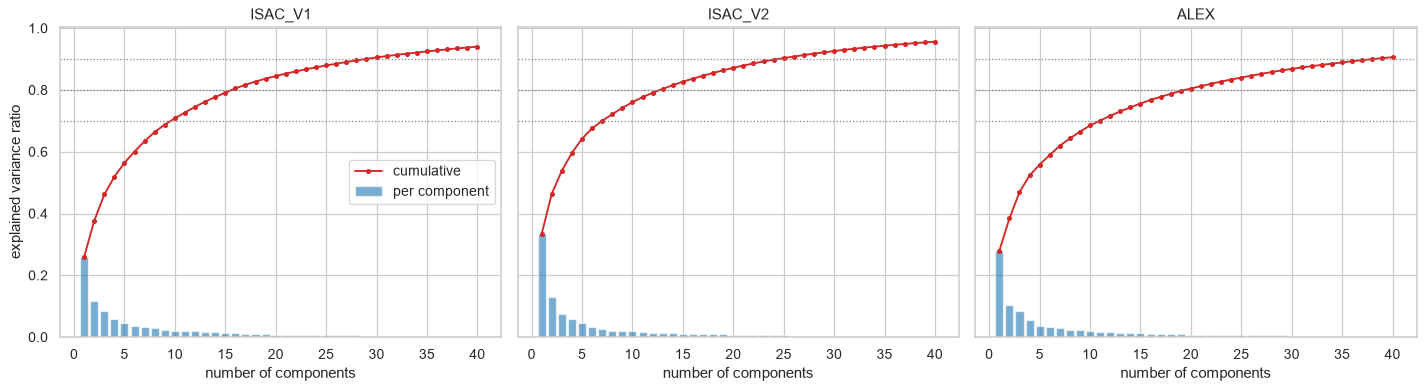

In [3]:
pcas = {chip: PCA().fit(X[chip]) for chip in CHIPS}

N_SHOW = 40
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, chip in zip(axes, CHIPS):
    ratio = pcas[chip].explained_variance_ratio_[:N_SHOW]
    ranks = np.arange(1, len(ratio) + 1)
    ax.bar(ranks, ratio, color="tab:blue", alpha=0.6, label="per component")
    ax.plot(ranks, np.cumsum(ratio), color="tab:red", marker=".", label="cumulative")
    for level in (0.7, 0.8, 0.9):
        ax.axhline(level, color="grey", ls=":", lw=1)
    ax.set_title(chip)
    ax.set_xlabel("number of components")
axes[0].set_ylabel("explained variance ratio")
axes[0].legend(loc="center right")
plt.tight_layout()
plt.show()

Nombre de composantes nécessaires pour atteindre 70 %, 80 % et 90 % de variance :

In [4]:
def n_components_for(pca, level):
    return int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), level) + 1)

summary = pd.DataFrame({
    chip: {
        "allergens": X[chip].shape[1],
        "PC1 %": round(100 * pcas[chip].explained_variance_ratio_[0], 1),
        **{f"k for {int(100 * lvl)}%": n_components_for(pcas[chip], lvl) for lvl in (0.7, 0.8, 0.9)},
    }
    for chip in CHIPS
}).T
summary

,allergens,PC1 %,k for 70%,k for 80%,k for 90%
ISAC_V1,112.0,25.9,10.0,16.0,29.0
ISAC_V2,112.0,33.5,7.0,13.0,25.0
ALEX,223.0,27.9,11.0,20.0,39.0


## 3. Que capturent les premières composantes ?

Avant de regarder les résidus, un coup d'œil aux premières composantes aide à les interpréter. On affiche les allergènes qui pèsent le plus (en valeur absolue) sur PC1 et PC2.

In [5]:
def top_loadings(chip, pc, n=8):
    load = pd.Series(pcas[chip].components_[pc], index=X[chip].columns)
    return load.reindex(load.abs().sort_values(ascending=False).index).head(n).round(2)

for chip in CHIPS:
    print(f"=== {chip}")
    for pc in (0, 1):
        items = ", ".join(f"{k} ({v:+.2f})" for k, v in top_loadings(chip, pc).items())
        print(f"  PC{pc + 1}: {items}")

=== ISAC_V1
  PC1: Phl_p_1 (+0.31), Der_f_2 (+0.28), Der_p_2 (+0.27), Der_p_1 (+0.25), Cyn_d_1 (+0.24), Der_f_1 (+0.24), Fel_d_1 (+0.23), Bet_v_1 (+0.22)
  PC2: Der_f_2 (+0.43), Der_p_2 (+0.42), Der_p_1 (+0.36), Der_f_1 (+0.34), Phl_p_5 (-0.24), Phl_p_1 (-0.20), Bet_v_1 (-0.19), Cyn_d_1 (-0.17)
=== ISAC_V2
  PC1: Bet_v_1 (+0.29), Der_p_2 (+0.29), Der_f_2 (+0.27), Der_p_1 (+0.25), Phl_p_1 (+0.25), Mal_d_1 (+0.22), Der_f_1 (+0.21), Der_p_23 (+0.20)
  PC2: Der_p_2 (+0.37), Der_f_2 (+0.36), Der_p_1 (+0.35), Der_f_1 (+0.29), Bet_v_1 (-0.28), Der_p_23 (+0.25), Mal_d_1 (-0.23), Pru_p_1 (-0.20)
=== ALEX
  PC1: Bet_v_1 (+0.27), Phl_p_1 (+0.26), Cor_a_1.0103 (+0.25), Lol_p_1 (+0.23), Fag_s_1 (+0.23), Fra_a_1+3 (+0.19), Cor_a_pollen (+0.19), Der_f_2 (+0.18)
  PC2: Der_f_2 (+0.35), Der_p_2 (+0.35), Der_p_1 (+0.27), Der_f_1 (+0.27), Der_p_23 (+0.25), Bet_v_1 (-0.18), Lep_d_2 (+0.17), Cor_a_1.0103 (-0.17)


Projection des patients sur le premier plan factoriel, colorée par le nombre d'allergènes positifs (IgE ≥ 0,3) :

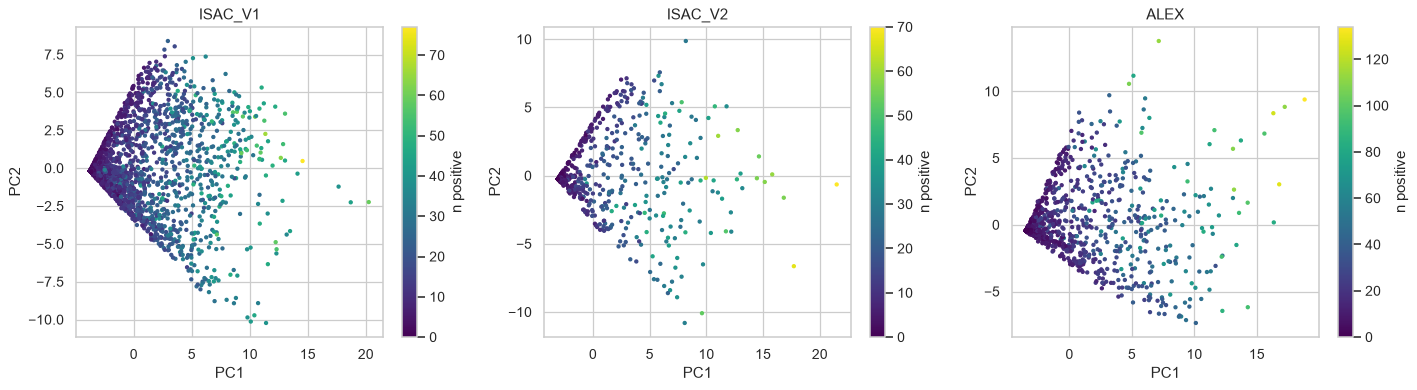

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, chip in zip(axes, CHIPS):
    scores = pcas[chip].transform(X[chip])
    n_pos = (np.expm1(X[chip]) >= 0.3).sum(axis=1)
    sc = ax.scatter(scores[:, 0], scores[:, 1], c=n_pos, cmap="viridis", s=6)
    ax.set_title(chip)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    fig.colorbar(sc, ax=ax, label="n positive")
plt.tight_layout()
plt.show()

## 4. Résidus de reconstruction

On garde les `k` premières composantes, avec `k` choisi pour atteindre **80 % de variance** (à ajuster). Pour chaque patient, on projette son profil sur ces `k` composantes, on le reconstruit, et on mesure l'erreur :

$$\text{résidu}_i = \lVert x_i - \hat{x}_i \rVert^2$$

(appelé aussi SPE ou statistique Q). Un résidu élevé veut dire que le profil du patient **ne ressemble pas** aux grandes tendances de sa puce : combinaison rare d'allergènes, valeur aberrante, ou erreur d'enregistrement.

On marque comme suspects les patients au-delà du **99ᵉ percentile** de leur puce. Ce seuil est arbitraire : c'est un outil pour repérer des cas à inspecter, pas un test statistique.

In [7]:
VARIANCE_LEVEL = 0.8

residuals = {}
for chip in CHIPS:
    k = n_components_for(pcas[chip], VARIANCE_LEVEL)
    pca_k = PCA(n_components=k).fit(X[chip])
    X_hat = pca_k.inverse_transform(pca_k.transform(X[chip]))
    residuals[chip] = pd.Series(((X[chip].values - X_hat) ** 2).sum(axis=1),
                                index=X[chip].index, name="residual")
    print(f"{chip:8s}: k = {k:2d} components")

ISAC_V1 : k = 16 components
ISAC_V2 : k = 13 components
ALEX    : k = 20 components


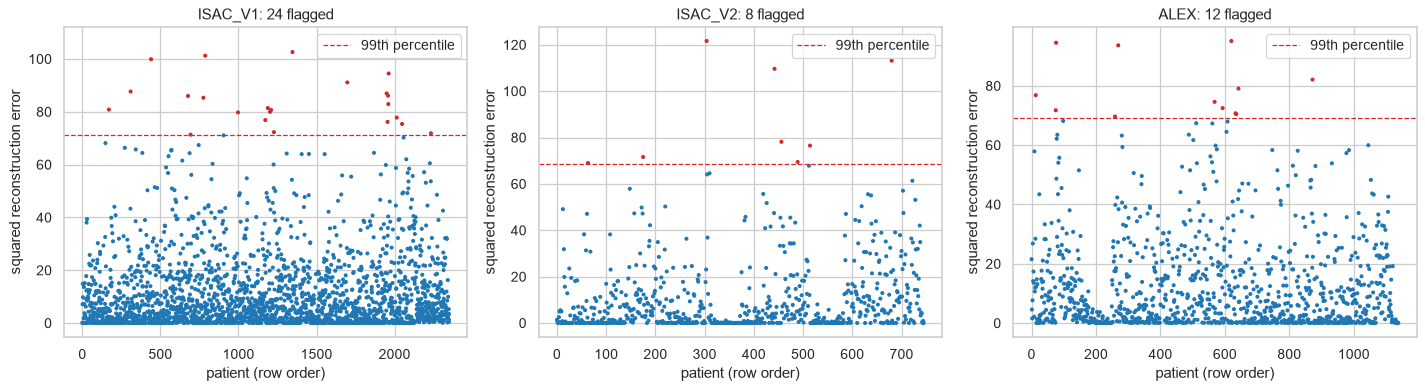

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, chip in zip(axes, CHIPS):
    res = residuals[chip]
    threshold = res.quantile(0.99)
    outlier = res > threshold
    ax.scatter(np.arange(len(res)), res, s=5, c=np.where(outlier, "tab:red", "tab:blue"))
    ax.axhline(threshold, color="tab:red", ls="--", lw=1, label="99th percentile")
    ax.set_title(f"{chip}: {outlier.sum()} flagged")
    ax.set_xlabel("patient (row order)")
    ax.set_ylabel("squared reconstruction error")
    ax.legend()
plt.tight_layout()
plt.show()

Distribution des résidus, pour voir si les patients signalés se détachent vraiment ou s'ils sont juste la queue d'une distribution continue :

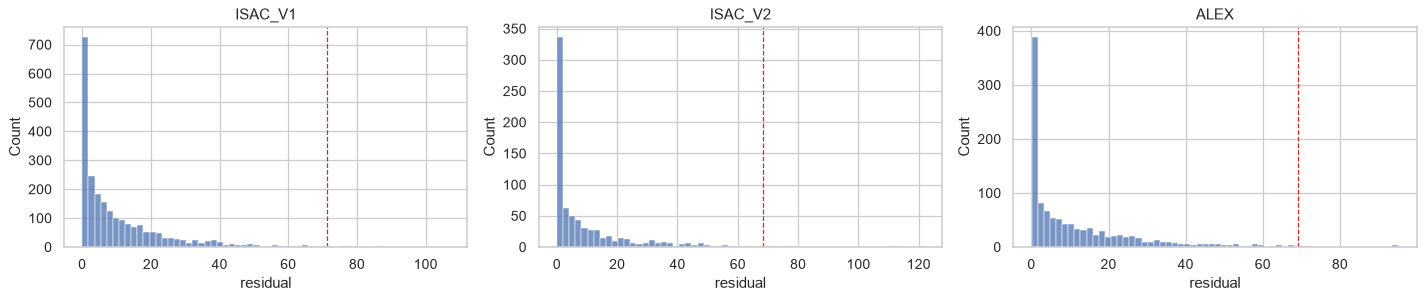

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, chip in zip(axes, CHIPS):
    sns.histplot(residuals[chip], bins=60, ax=ax)
    ax.axvline(residuals[chip].quantile(0.99), color="tab:red", ls="--", lw=1)
    ax.set_title(chip)
plt.tight_layout()
plt.show()

### Qui sont les patients au plus gros résidu ?

Pour les 5 patients au plus gros résidu de chaque puce, on affiche leur âge, leur nombre d'allergènes positifs, et les allergènes qui contribuent le plus à leur erreur de reconstruction.

In [10]:
rows = []
for chip in CHIPS:
    k = n_components_for(pcas[chip], VARIANCE_LEVEL)
    pca_k = PCA(n_components=k).fit(X[chip])
    err = X[chip] - pca_k.inverse_transform(pca_k.transform(X[chip]))
    for idx in residuals[chip].nlargest(5).index:
        contrib = (err.loc[idx] ** 2).nlargest(3)
        raw = np.expm1(X[chip].loc[idx])
        rows.append({
            "chip": chip,
            "patient": df.loc[idx, "Patient_ID"],
            "age": df.loc[idx, "Age"],
            "residual": round(residuals[chip][idx], 1),
            "n_positive": int((raw >= 0.3).sum()),
            "top contributors (raw IgE)": ", ".join(f"{a} ({raw[a]:.1f})" for a in contrib.index),
        })
pd.DataFrame(rows)

,chip,patient,age,residual,n_positive,top contributors (raw IgE)
0,ISAC_V1,XPW0114,57.0,106.8,49,"Lep_d_2 (130.0), Jug_r_2 (90.0), Fel_d_2 (28.8)"
1,ISAC_V1,QVW1083,6.0,102.6,40,"Amb_a_1 (140.9), Gal_d_3 (134.7), Gal_d_1 (154.1)"
2,ISAC_V1,QVW0524,4.0,101.3,57,"Pen_m_4 (60.8), Can_f_3 (69.5), Gal_d_5 (23.0)"
3,ISAC_V1,QVW0177,8.0,99.9,66,"Blo_t_5 (71.1), Can_f_3 (114.1), Phl_p_2 (0.0)"
4,ISAC_V1,XPW0126,54.0,94.5,47,"Hev_b_5 (40.5), Hev_b_6.01 (39.8), Pen_m_2 (77.2)"
5,ISAC_V2,PMP0166,10.0,121.6,18,"Bla_g_1 (139.0), Bla_g_5 (123.3), Bla_g_2 (115.2)"
6,ISAC_V2,WQW0108,4.0,113.1,50,"Phl_p_7 (69.5), Can_f_1 (0.0), Alt_a_1 (0.0)"
7,ISAC_V2,TFG0176,8.0,109.6,38,"Gad_c_1 (183.7), Pen_m_4 (65.3), Gal_d_5 (69.1)"
8,ISAC_V2,TFG0190,16.0,78.2,54,"Lep_d_2 (153.3), Gad_c_1 (67.7), Pen_m_2 (40.2)"
9,ISAC_V2,TFG0249,52.0,76.5,29,"Par_j_2 (120.9), Pla_a_3 (19.2), Art_v_1 (20.4)"


## 5. Ce qu'on retient

**Variance expliquée**
- PC1 explique à elle seule 26 à 34 % de la variance. Tous ses poids sont positifs : c'est un axe **« intensité globale de sensibilisation »**, très lié au nombre d'allergènes positifs (le dégradé de couleur suit PC1).
- PC2 oppose les **acariens** (`Der_p`, `Der_f`) aux **pollens** (`Phl_p`, `Bet_v_1`) : premier axe vraiment interprétable en termes de profil allergique.
- Il n'y a pas de coude net après les 4 ou 5 premières composantes, la variance décroît ensuite lentement. Pour 80 % de variance, il faut 13 (ISAC v2), 16 (ISAC v1) ou 20 (ALEX) composantes. L'information est donc assez dispersée : quelques axes résument les grands profils, mais beaucoup d'allergènes ont un comportement propre.
- La forme en « triangle » du plan PC1–PC2 (beaucoup de patients collés à l'origine, puis un éventail) est typique de données gonflées en zéros. Une PCA linéaire n'est pas le modèle idéal pour ce type de données.

**Résidus**
- La distribution des résidus est une queue continue : aucun groupe de patients ne se détache franchement.
- Les patients signalés sont tous **fortement polysensibilisés** (40 à 113 allergènes positifs), avec des sensibilisations rares mais cohérentes : par exemple trois allergènes de blatte (`Bla_g_1/2/5`) chez le même patient, ou les deux allergènes du latex (`Hev_b_5/6`). Ce sont des **profils atypiques plausibles**, pas des erreurs d'enregistrement.
- Le résidu brut grandit mécaniquement avec l'intensité du profil : un patient avec beaucoup d'IgE élevées a plus de chances d'être mal reconstruit.
- Le vrai problème de qualité de données trouvé ici, ce sont les **52 valeurs à `-1`**, désormais traitées comme manquantes.
- Les graphiques par ordre de ligne montrent des **blocs** (notamment sur ISAC v2). Les lignes étant triées par identifiant, donc probablement par centre, certains centres semblent avoir beaucoup de patients non sensibilisés. Il faudra vérifier un éventuel effet centre.